In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

In [11]:
data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(f"Shape: {X.shape}\nClasses: {data.target_names}")
display(X.head())

Shape: (178, 13)
Classes: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [13]:
model = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
all_acc = accuracy_score(y_test, model.predict(X_test))
print(f"Accuracy with ALL features: {all_acc:.4f}")

Accuracy with ALL features: 0.9556


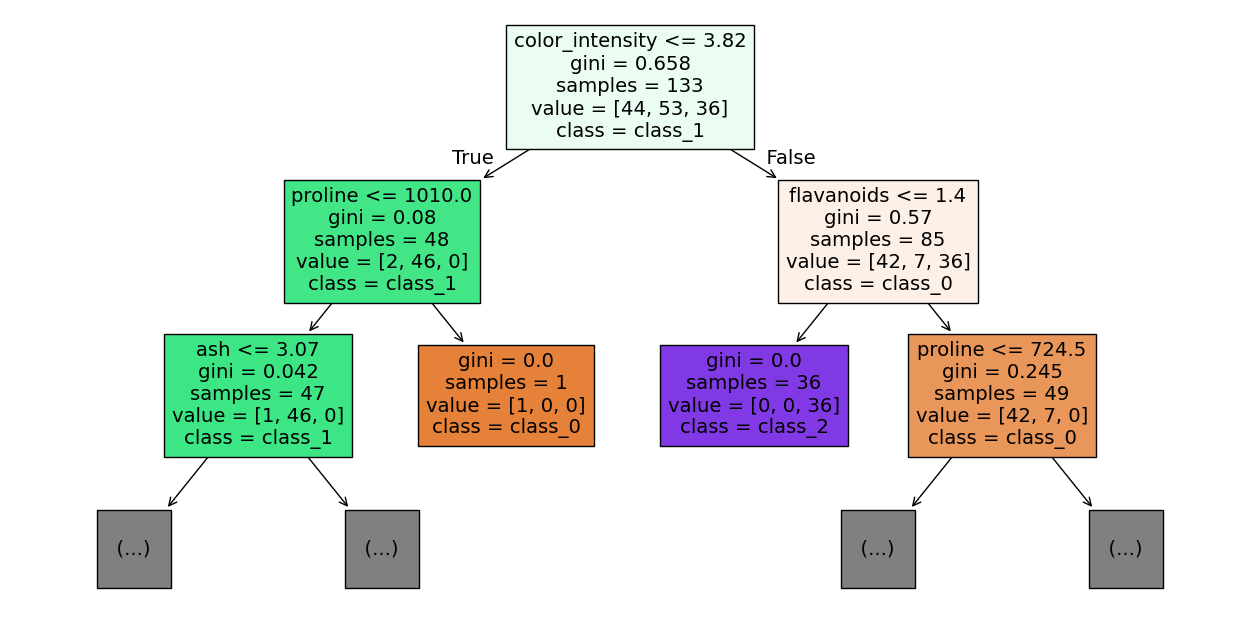

In [14]:
plt.figure(figsize=(16, 8))
plot_tree(model, feature_names=X.columns, class_names=data.target_names, filled=True, max_depth=2)
plt.show()

flavanoids                      0.415894
color_intensity                 0.403317
proline                         0.138457
ash                             0.022351
alcohol                         0.019982
magnesium                       0.000000
alcalinity_of_ash               0.000000
malic_acid                      0.000000
total_phenols                   0.000000
proanthocyanins                 0.000000
nonflavanoid_phenols            0.000000
hue                             0.000000
od280/od315_of_diluted_wines    0.000000
dtype: float64


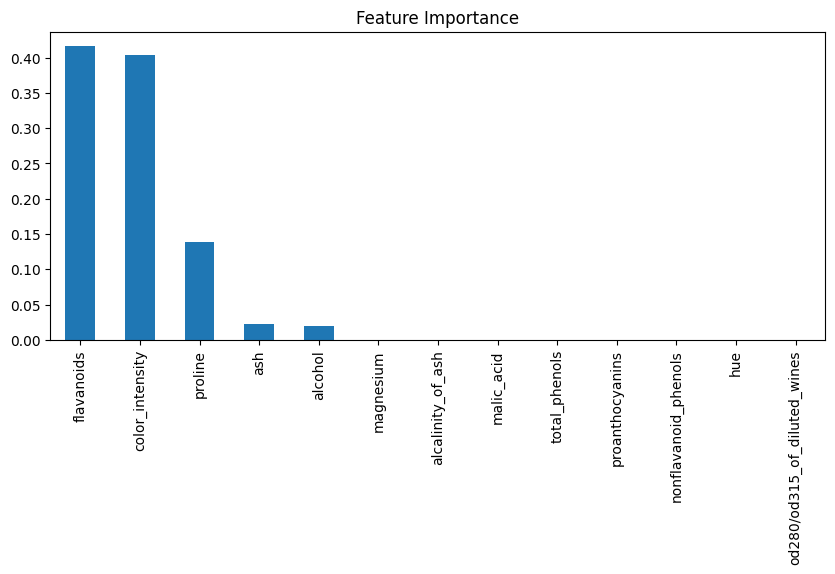

In [15]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance)
importance.plot(kind='bar', figsize=(10, 4), title='Feature Importance')
plt.show()

In [16]:
subsets = {
    'All features': list(X.columns),
    'Top 3 important': list(importance.index[:3]),
    'Bottom 3 important': list(importance.index[-3:]),
    'First 3 columns': list(X.columns[:3])
}

for name, cols in subsets.items():
    print(f"{name} -> {cols}")

All features -> ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Top 3 important -> ['flavanoids', 'color_intensity', 'proline']
Bottom 3 important -> ['nonflavanoid_phenols', 'hue', 'od280/od315_of_diluted_wines']
First 3 columns -> ['alcohol', 'malic_acid', 'ash']


In [17]:
results = pd.Series({
    name: accuracy_score(y_test, DecisionTreeClassifier(random_state=42).fit(X_train[cols], y_train).predict(X_test[cols]))
    for name, cols in subsets.items()
})
print(results)

All features          0.955556
Top 3 important       0.933333
Bottom 3 important    0.688889
First 3 columns       0.666667
dtype: float64


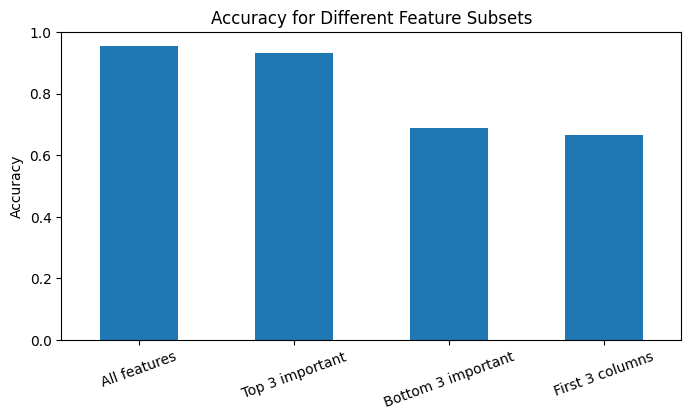

In [18]:
results.plot(kind='bar', figsize=(8, 4), title='Accuracy for Different Feature Subsets', ylim=(0, 1), rot=20)
plt.ylabel('Accuracy')
plt.show()